In [432]:
# Importamos las librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets, linear_model
from sklearn.metrics import mean_squared_error, r2_score
# Importamos la librería LabelEncoder de sklearn.preprocessing
from sklearn.preprocessing import LabelEncoder
%matplotlib inline

In [433]:
# Creamos una instancia de linear_model.LinearRegression
regr = linear_model.LinearRegression()

In [434]:
# Creamos una instancia de labelEncoder
le = LabelEncoder()

In [435]:
# Leemos el dataset
data_url = './dataset/Medals.csv'
df = pd.read_csv(data_url, sep=',',encoding= 'latin1') #unicode_escape

### Análisis exploratorio

In [436]:
df.head()

,Athlete,Age,Year,Closing Ceremony Date,Gold Medals,Silver Medals,Bronze Medals,Total Medals
0,Michael Phelps,23.0,2008,08/24/2008,8,0,0,8
1,Michael Phelps,19.0,2004,08/29/2004,6,0,2,8
2,Michael Phelps,27.0,2012,08/12/2012,4,2,0,6
3,Natalie Coughlin,25.0,2008,08/24/2008,1,2,3,6
4,Aleksey Nemov,24.0,2000,10/01/2000,2,1,3,6


In [437]:
# Podemos fijarnos que algunos atletas se repiten
df.query("Athlete == 'Michael Phelps'").count()[0]

3

In [438]:
df.tail()

,Athlete,Age,Year,Closing Ceremony Date,Gold Medals,Silver Medals,Bronze Medals,Total Medals
8613,Olena Sadovnycha,32.0,2000,10/01/2000,0,1,0,1
8614,Kateryna Serdiuk,17.0,2000,10/01/2000,0,1,0,1
8615,Wietse van Alten,21.0,2000,10/01/2000,0,0,1,1
8616,Sandra Wagner-Sachse,31.0,2000,10/01/2000,0,0,1,1
8617,Rod White,23.0,2000,10/01/2000,0,0,1,1


In [439]:
df.sample(5)

,Athlete,Age,Year,Closing Ceremony Date,Gold Medals,Silver Medals,Bronze Medals,Total Medals
1859,Sandra aric,24.0,2008,08/24/2008,0,0,1,1
6365,Levi Leipheimer,34.0,2008,08/24/2008,0,0,1,1
6164,Ellen Bontje,42.0,2000,10/01/2000,0,1,0,1
3753,Zhaneta Ilieva,19.0,2004,08/29/2004,0,0,1,1
6598,Nikolay Morilov,23.0,2010,02/28/2010,0,0,1,1


In [440]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8618 entries, 0 to 8617
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Athlete                8613 non-null   object 
 1   Age                    8613 non-null   float64
 2   Year                   8618 non-null   int64  
 3   Closing Ceremony Date  8618 non-null   object 
 4   Gold Medals            8618 non-null   int64  
 5   Silver Medals          8618 non-null   int64  
 6   Bronze Medals          8618 non-null   int64  
 7   Total Medals           8618 non-null   int64  
dtypes: float64(1), int64(5), object(2)
memory usage: 538.8+ KB


In [441]:
df.dtypes

Athlete                   object
Age                      float64
Year                       int64
Closing Ceremony Date     object
Gold Medals                int64
Silver Medals              int64
Bronze Medals              int64
Total Medals               int64
dtype: object

In [442]:
# Contamos los valores nulos de cada columna
df.isnull().sum()

Athlete                  5
Age                      5
Year                     0
Closing Ceremony Date    0
Gold Medals              0
Silver Medals            0
Bronze Medals            0
Total Medals             0
dtype: int64

In [443]:
# Nombres de las características
for x in df.columns:
    print("El nombre de la característica es",x)

El nombre de la característica es Athlete
El nombre de la característica es Age
El nombre de la característica es Year
El nombre de la característica es Closing Ceremony Date
El nombre de la característica es Gold Medals
El nombre de la característica es Silver Medals
El nombre de la característica es Bronze Medals
El nombre de la característica es Total Medals


In [444]:
# Valores únicos
# Aquí se presentan muchos valores únicos, sólo serán contados.
len(df["Athlete"].unique())

6956

In [445]:
df["Age"].unique()

array([23., 19., 27., 25., 24., 17., 22., 21., 33., 26., 18., 29., 20.,
       30., 28., 16., 32., 41., 15., 34., 31., 35., 37., 38., 46., 40.,
       44., 45., 39., 42., 36., nan, 49., 43., 47., 52., 50., 54., 51.,
       56., 55., 61., 48.])

In [446]:
df["Year"].unique()

array([2008, 2004, 2012, 2000, 2006, 2010, 2002], dtype=int64)

In [447]:
df["Closing Ceremony Date"].unique()

array(['08/24/2008', '08/29/2004', '08/12/2012', '10/01/2000',
       '02/26/2006', '02/28/2010', '02/24/2002'], dtype=object)

In [448]:
df["Gold Medals"].unique()

array([8, 6, 4, 1, 2, 3, 0], dtype=int64)

In [449]:
df["Silver Medals"].unique()

array([0, 2, 1, 3], dtype=int64)

In [450]:
df["Bronze Medals"].unique()

array([0, 2, 3, 1], dtype=int64)

In [451]:
df["Total Medals"].unique()

array([8, 6, 5, 4, 3, 2, 1], dtype=int64)

In [452]:
# Tamaño del dataset
df.shape

(8618, 8)

In [453]:
# Cantidad de Características
df.shape[1]

8

In [454]:
# Cantidad de observaciones
df.shape[0]

8618

In [455]:
# Cantidad de Características con datos Cualitativos / Categóricos 
# Agrupación de las columnas por tipo de datos
tipos = df.columns.to_series().groupby(df.dtypes).groups
ctext = tipos[np.dtype('object')]
len(ctext)

2

In [456]:
# Cantidad de características con datos Cuantitativos / Numéricos
columnas = df.columns
cnum = list(set(columnas) - set(ctext))
len(cnum)

6

### Preprocesamiento de los datos

In [457]:
df2 = df

In [458]:
# Limpieza, al ser tan pocos los registros nulos, podemos eliminar las filas que contengan nulos
df2.dropna(inplace = True)

In [459]:
df2.isnull().sum()

Athlete                  0
Age                      0
Year                     0
Closing Ceremony Date    0
Gold Medals              0
Silver Medals            0
Bronze Medals            0
Total Medals             0
dtype: int64

In [460]:
# Transformar las estaciones
df2['Athlete_Encoder'] = le.fit_transform(df2.Athlete.values)
df2.tail(3)

,Athlete,Age,Year,Closing Ceremony Date,Gold Medals,Silver Medals,Bronze Medals,Total Medals,Athlete_Encoder
8615,Wietse van Alten,21.0,2000,10/01/2000,0,0,1,1,6545
8616,Sandra Wagner-Sachse,31.0,2000,10/01/2000,0,0,1,1,5505
8617,Rod White,23.0,2000,10/01/2000,0,0,1,1,5313


In [461]:
# Variable Categórica Date
# Parseamos la variable de la fecha a datetime para utilizar sus propiedades
# Establecemos como indíce del dataframe porque es el identificador de los días
df2['Closing Ceremony Date'] = pd.to_datetime(df2['Closing Ceremony Date'], errors='coerce')
df2.set_index('Closing Ceremony Date',inplace = True)

In [462]:
def info_datetime(df,lista):
    return pd.DataFrame({
        'anio': df.index[lista].year,
        'mes': df.index[lista].month,
        'nombre_mes': df.index[lista].month_name(),
        'dia_anio': df.index[lista].dayofyear,
        'dia': df.index[lista].day,
        'dia_semana': df.index[lista].dayofweek,
        'dia_nombre': df.index[lista].day_name(),
        'hora': df.index[lista].hour,
        'minuto': df.index[lista].minute
    })

In [463]:
info_datetime(df2, [0,1,2,3,4,5])

,anio,mes,nombre_mes,dia_anio,dia,dia_semana,dia_nombre,hora,minuto
0,2008,8,August,237,24,6,Sunday,0,0
1,2004,8,August,242,29,6,Sunday,0,0
2,2012,8,August,225,12,6,Sunday,0,0
3,2008,8,August,237,24,6,Sunday,0,0
4,2000,10,October,275,1,6,Sunday,0,0
5,2012,8,August,225,12,6,Sunday,0,0


In [464]:
df2['Month'] = df2.index.month

In [465]:
df2['Day'] = df2.index.day

In [466]:
df2.sample()

,Athlete,Age,Year,Gold Medals,Silver Medals,Bronze Medals,Total Medals,Athlete_Encoder,Month,Day
Closing Ceremony Date,,,,,,,,,,
2012-08-12,Endéné Miyem,24.0,2012,0,1,0,1,1768,8,12


In [467]:
df2.drop('Athlete', axis=1, inplace = True)

In [468]:
# Creamos funciones para hacer los gráficos
def graficoCajaBigotes(feature,labelx, labely,title):
    plt.boxplot(df[feature])
    plt.ylabel(labely)
    plt.xlabel(labelx)
    plt.title(title)
    
def graficoLineas(xvalue,yvalue,title):
    df.plot(kind="scatter",x=xvalue,y=yvalue,title=title)

In [469]:
# Calcular coeficientes de correlación de cada una de las variables.
# Exceptuando x vs x
cantidad = len(df2.columns)
columnas = df2.columns

for x in columnas:
    print(x)
# Calculamos la cantidad de combinaciones posibles para estimar su coeficiente de correlación
print("La cantidad de columnas son ",cantidad, " y la cantidad de combinaciones son", cantidad * (cantidad - 1))

Age
Year
Gold Medals
Silver Medals
Bronze Medals
Total Medals
Athlete_Encoder
Month
Day
La cantidad de columnas son  9  y la cantidad de combinaciones son 72


,Age,Year,Gold Medals,Silver Medals,Bronze Medals,Total Medals,Athlete_Encoder,Month,Day
Closing Ceremony Date,,,,,,,,,
2008-08-24,23.0,2008,8,0,0,8,4315,8,24
2004-08-29,19.0,2004,6,0,2,8,4315,8,29
2012-08-12,27.0,2012,4,2,0,6,4315,8,12
2008-08-24,25.0,2008,1,2,3,6,4557,8,24
2000-10-01,24.0,2000,2,1,3,6,161,10,1
...,...,...,...,...,...,...,...,...,...
2000-10-01,32.0,2000,0,1,0,1,4820,10,1
2000-10-01,17.0,2000,0,1,0,1,3141,10,1
2000-10-01,21.0,2000,0,0,1,1,6545,10,1


In [428]:
#coeficioente de correlacion (coeficiente correlacion de pearson)

# AGE
print(np.corrcoef(df2[columnas[0]],df2[columnas[1]])[0,1])
print(np.corrcoef(df2[columnas[0]],df2[columnas[2]])[0,1])
print(np.corrcoef(df2[columnas[0]],df2[columnas[3]])[0,1])
print(np.corrcoef(df2[columnas[0]],df2[columnas[4]])[0,1])
print(np.corrcoef(df2[columnas[0]],df2[columnas[5]])[0,1])
print(np.corrcoef(df2[columnas[0]],df2[columnas[6]])[0,1])
print(np.corrcoef(df2[columnas[0]],df2[columnas[7]])[0,1])
print(np.corrcoef(df2[columnas[0]],df2[columnas[8]])[0,1])

-0.006813925072861459
-0.029553241329374567
-0.011228920677518692
-0.015306385135620505
-0.07235683052681521
-0.017484472904897568
-0.057928244991319454
0.022992325663340366


In [532]:
def uwu(index):
    for x in range(0,cantidad):
        if(index != x):
            print(np.corrcoef(df2[columnas[index]],df2[columnas[x]])[0,1])
uwu(0)

-0.006813925072861459
-0.029553241329374567
-0.011228920677518692
-0.015306385135620505
-0.07235683052681521
-0.017484472904897568
-0.057928244991319454
0.022992325663340366


<AxesSubplot:xlabel='Age', ylabel='Day'>

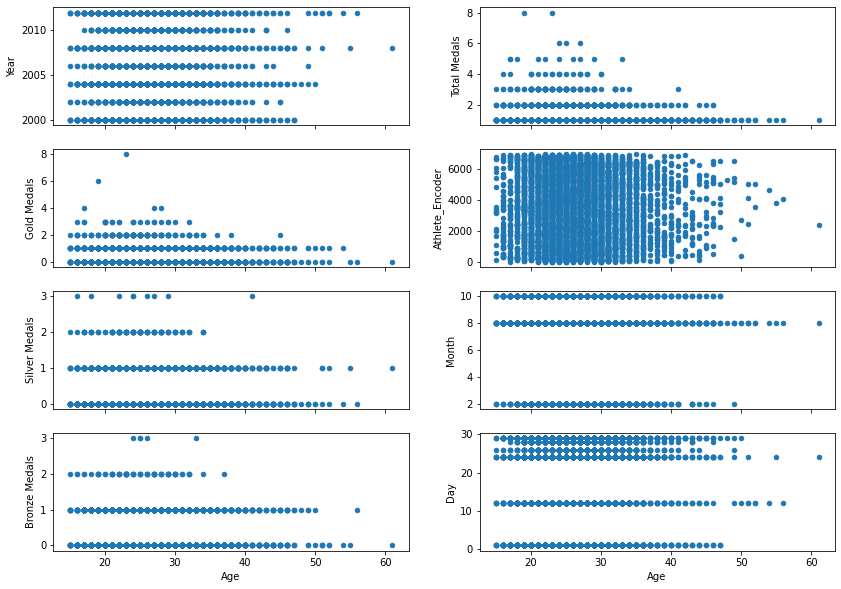

In [497]:
# Age
figure, axs = plt.subplots(4,2,figsize = (14,10), sharey=False, sharex=True)
df2.plot(kind="scatter",x=columnas[0],y=columnas[1],ax=axs[0][0])
df2.plot(kind="scatter",x=columnas[0],y=columnas[2],ax=axs[1][0])
df2.plot(kind="scatter",x=columnas[0],y=columnas[3],ax=axs[2][0])
df2.plot(kind="scatter",x=columnas[0],y=columnas[4],ax=axs[3][0])
df2.plot(kind="scatter",x=columnas[0],y=columnas[5],ax=axs[0][1])
df2.plot(kind="scatter",x=columnas[0],y=columnas[6],ax=axs[1][1])
df2.plot(kind="scatter",x=columnas[0],y=columnas[7],ax=axs[2][1])
df2.plot(kind="scatter",x=columnas[0],y=columnas[8],ax=axs[3][1])

In [429]:
# YEAR
print(np.corrcoef(df2[columnas[1]],df2[columnas[0]])[0,1])
print(np.corrcoef(df2[columnas[1]],df2[columnas[2]])[0,1])
print(np.corrcoef(df2[columnas[1]],df2[columnas[3]])[0,1])
print(np.corrcoef(df2[columnas[1]],df2[columnas[4]])[0,1])
print(np.corrcoef(df2[columnas[1]],df2[columnas[5]])[0,1])
print(np.corrcoef(df2[columnas[1]],df2[columnas[6]])[0,1])
print(np.corrcoef(df2[columnas[1]],df2[columnas[7]])[0,1])
print(np.corrcoef(df2[columnas[1]],df2[columnas[8]])[0,1])

-0.006813925072861458
-0.002414355633240409
-0.0015379492497619148
0.010084323804110945
0.0073097269469807715
-0.013778698676566456
-0.25358266837342847
0.28994273092554984


<AxesSubplot:xlabel='Year', ylabel='Day'>

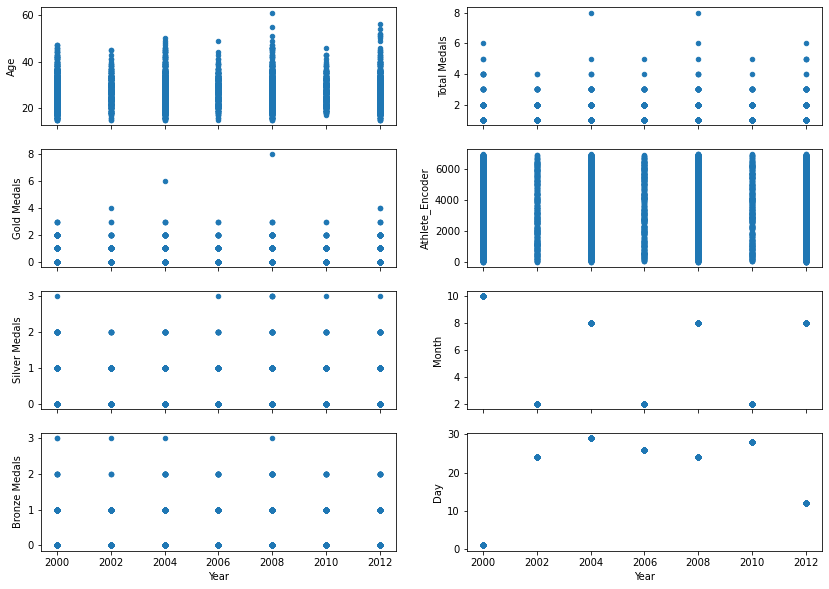

In [496]:
# Year
figure, axs = plt.subplots(4,2,figsize = (14,10), sharey=False, sharex=True)
df2.plot(kind="scatter",x=columnas[1],y=columnas[0],ax=axs[0][0])
df2.plot(kind="scatter",x=columnas[1],y=columnas[2],ax=axs[1][0])
df2.plot(kind="scatter",x=columnas[1],y=columnas[3],ax=axs[2][0])
df2.plot(kind="scatter",x=columnas[1],y=columnas[4],ax=axs[3][0])
df2.plot(kind="scatter",x=columnas[1],y=columnas[5],ax=axs[0][1])
df2.plot(kind="scatter",x=columnas[1],y=columnas[6],ax=axs[1][1])
df2.plot(kind="scatter",x=columnas[1],y=columnas[7],ax=axs[2][1])
df2.plot(kind="scatter",x=columnas[1],y=columnas[8],ax=axs[3][1])

In [506]:
# GOLD MEDALS
print(np.corrcoef(df2[columnas[2]],df2[columnas[0]])[0,1])
print(np.corrcoef(df2[columnas[2]],df2[columnas[1]])[0,1])
print(np.corrcoef(df2[columnas[2]],df2[columnas[3]])[0,1])
print(np.corrcoef(df2[columnas[2]],df2[columnas[4]])[0,1])
print(np.corrcoef(df2[columnas[2]],df2[columnas[5]])[0,1])
print(np.corrcoef(df2[columnas[2]],df2[columnas[6]])[0,1])
print(np.corrcoef(df2[columnas[2]],df2[columnas[7]])[0,1])
print(np.corrcoef(df2[columnas[2]],df2[columnas[8]])[0,1])

print("Valor más cercano a 1 :", np.corrcoef(df2[columnas[2]],df2[columnas[4]])[0,1])

-0.029553241329374567
-0.002414355633240409
-0.34864111862330965
-0.4032914048970575
0.39952152953813214
0.0034251468309624434
-0.02273976347006791
0.008331459529052355
Valor más cercano a 1 : -0.4032914048970575


<AxesSubplot:xlabel='Gold Medals', ylabel='Day'>

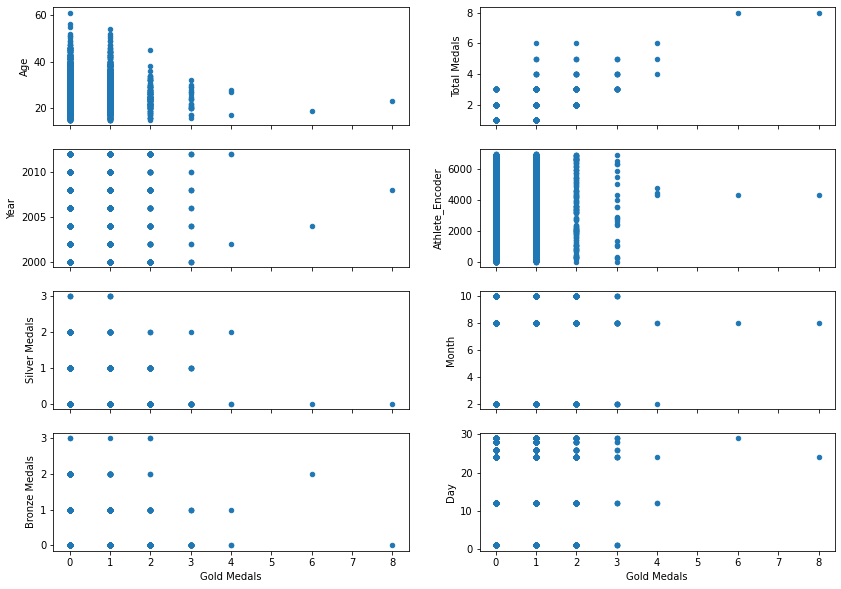

In [498]:
# Gold Medals
figure, axs = plt.subplots(4,2,figsize = (14,10), sharey=False, sharex=True)
df2.plot(kind="scatter",x=columnas[2],y=columnas[0],ax=axs[0][0])
df2.plot(kind="scatter",x=columnas[2],y=columnas[1],ax=axs[1][0])
df2.plot(kind="scatter",x=columnas[2],y=columnas[3],ax=axs[2][0])
df2.plot(kind="scatter",x=columnas[2],y=columnas[4],ax=axs[3][0])
df2.plot(kind="scatter",x=columnas[2],y=columnas[5],ax=axs[0][1])
df2.plot(kind="scatter",x=columnas[2],y=columnas[6],ax=axs[1][1])
df2.plot(kind="scatter",x=columnas[2],y=columnas[7],ax=axs[2][1])
df2.plot(kind="scatter",x=columnas[2],y=columnas[8],ax=axs[3][1])

In [507]:
# Silver Medals
print(np.corrcoef(df2[columnas[3]],df2[columnas[0]])[0,1])
print(np.corrcoef(df2[columnas[3]],df2[columnas[1]])[0,1])
print(np.corrcoef(df2[columnas[3]],df2[columnas[2]])[0,1])
print(np.corrcoef(df2[columnas[3]],df2[columnas[4]])[0,1])
print(np.corrcoef(df2[columnas[3]],df2[columnas[5]])[0,1])
print(np.corrcoef(df2[columnas[3]],df2[columnas[6]])[0,1])
print(np.corrcoef(df2[columnas[3]],df2[columnas[7]])[0,1])
print(np.corrcoef(df2[columnas[3]],df2[columnas[8]])[0,1])

print("Valor más cercano a 1 :",np.corrcoef(df2[columnas[3]],df2[columnas[4]])[0,1])

-0.011228920677518692
-0.0015379492497619148
-0.3486411186233097
-0.4455619788883029
0.23552345448213535
-0.002922067106928134
-0.022585178343374562
0.008069896265713972
Valor más cercano a 1 : -0.4455619788883029


<AxesSubplot:xlabel='Silver Medals', ylabel='Day'>

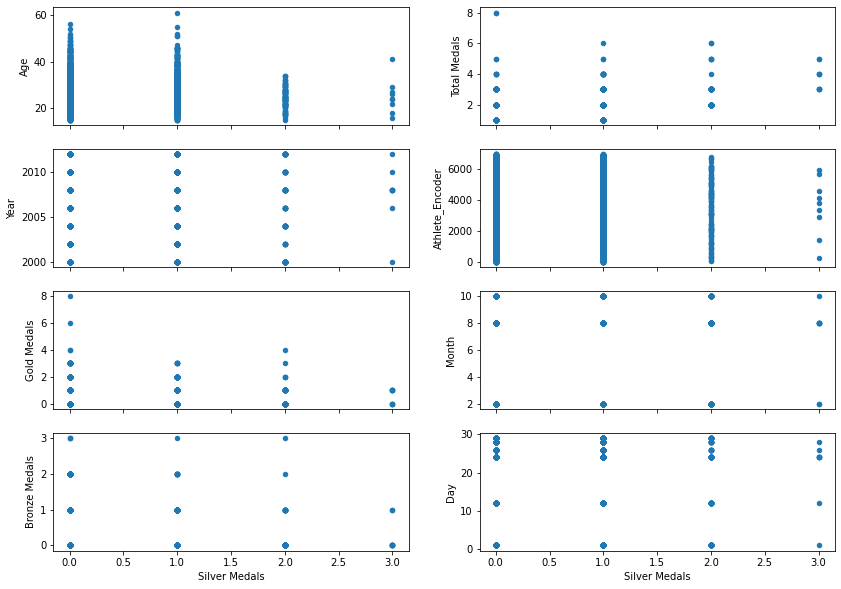

In [499]:
# Silver Medals
figure, axs = plt.subplots(4,2,figsize = (14,10), sharey=False, sharex=True)
df2.plot(kind="scatter",x=columnas[3],y=columnas[0],ax=axs[0][0])
df2.plot(kind="scatter",x=columnas[3],y=columnas[1],ax=axs[1][0])
df2.plot(kind="scatter",x=columnas[3],y=columnas[2],ax=axs[2][0])
df2.plot(kind="scatter",x=columnas[3],y=columnas[4],ax=axs[3][0])
df2.plot(kind="scatter",x=columnas[3],y=columnas[5],ax=axs[0][1])
df2.plot(kind="scatter",x=columnas[3],y=columnas[6],ax=axs[1][1])
df2.plot(kind="scatter",x=columnas[3],y=columnas[7],ax=axs[2][1])
df2.plot(kind="scatter",x=columnas[3],y=columnas[8],ax=axs[3][1])

In [509]:
# Bronze Medals
print(np.corrcoef(df2[columnas[4]],df2[columnas[0]])[0,1])
print(np.corrcoef(df2[columnas[4]],df2[columnas[1]])[0,1])
print(np.corrcoef(df2[columnas[4]],df2[columnas[2]])[0,1])
print(np.corrcoef(df2[columnas[4]],df2[columnas[3]])[0,1])
print(np.corrcoef(df2[columnas[4]],df2[columnas[5]])[0,1])
print(np.corrcoef(df2[columnas[4]],df2[columnas[6]])[0,1])
print(np.corrcoef(df2[columnas[4]],df2[columnas[7]])[0,1])
print(np.corrcoef(df2[columnas[4]],df2[columnas[8]])[0,1])

print("Valor más cercano a 1 :",np.corrcoef(df2[columnas[4]],df2[columnas[3]])[0,1])

-0.015306385135620505
0.010084323804110945
-0.4032914048970575
-0.4455619788883029
0.13980574198214807
-0.01056290099830229
-0.01230277883701616
0.003234733330190781
Valor más cercano a 1 : -0.4455619788883029


<AxesSubplot:xlabel='Bronze Medals', ylabel='Day'>

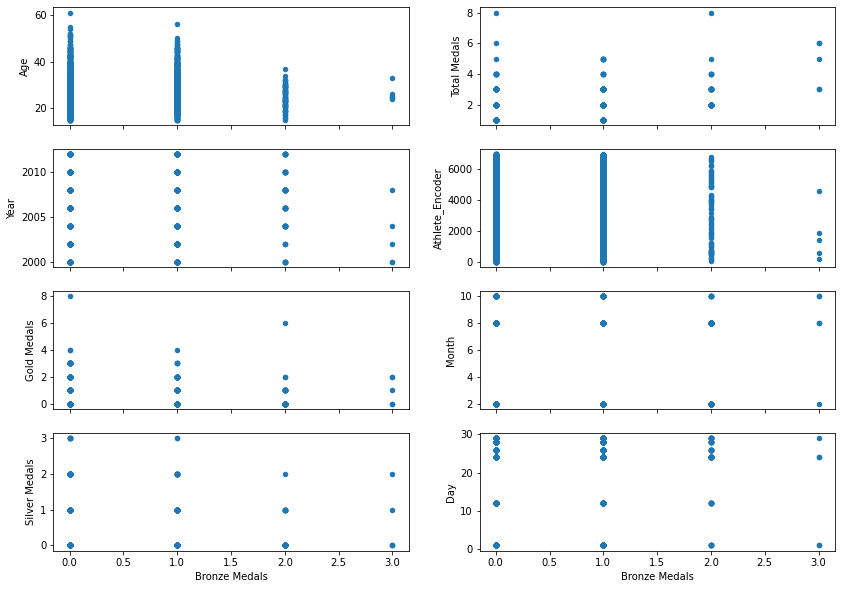

In [500]:
# Bronze Medals
figure, axs = plt.subplots(4,2,figsize = (14,10), sharey=False, sharex=True)
df2.plot(kind="scatter",x=columnas[4],y=columnas[0],ax=axs[0][0])
df2.plot(kind="scatter",x=columnas[4],y=columnas[1],ax=axs[1][0])
df2.plot(kind="scatter",x=columnas[4],y=columnas[2],ax=axs[2][0])
df2.plot(kind="scatter",x=columnas[4],y=columnas[3],ax=axs[3][0])
df2.plot(kind="scatter",x=columnas[4],y=columnas[5],ax=axs[0][1])
df2.plot(kind="scatter",x=columnas[4],y=columnas[6],ax=axs[1][1])
df2.plot(kind="scatter",x=columnas[4],y=columnas[7],ax=axs[2][1])
df2.plot(kind="scatter",x=columnas[4],y=columnas[8],ax=axs[3][1])

In [510]:
# Total Medals
print(np.corrcoef(df2[columnas[5]],df2[columnas[0]])[0,1])
print(np.corrcoef(df2[columnas[5]],df2[columnas[1]])[0,1])
print(np.corrcoef(df2[columnas[5]],df2[columnas[2]])[0,1])
print(np.corrcoef(df2[columnas[5]],df2[columnas[3]])[0,1])
print(np.corrcoef(df2[columnas[5]],df2[columnas[4]])[0,1])
print(np.corrcoef(df2[columnas[5]],df2[columnas[6]])[0,1])
print(np.corrcoef(df2[columnas[5]],df2[columnas[7]])[0,1])
print(np.corrcoef(df2[columnas[5]],df2[columnas[8]])[0,1])

print("Valor más cercano a 1 :",np.corrcoef(df2[columnas[5]],df2[columnas[2]])[0,1])

-0.07235683052681521
0.007309726946980771
0.39952152953813214
0.23552345448213538
0.1398057419821481
-0.01213079323042845
-0.07376447373374119
0.025197993783196367
Valor más cercano a 1 : 0.39952152953813214


<AxesSubplot:xlabel='Total Medals', ylabel='Day'>

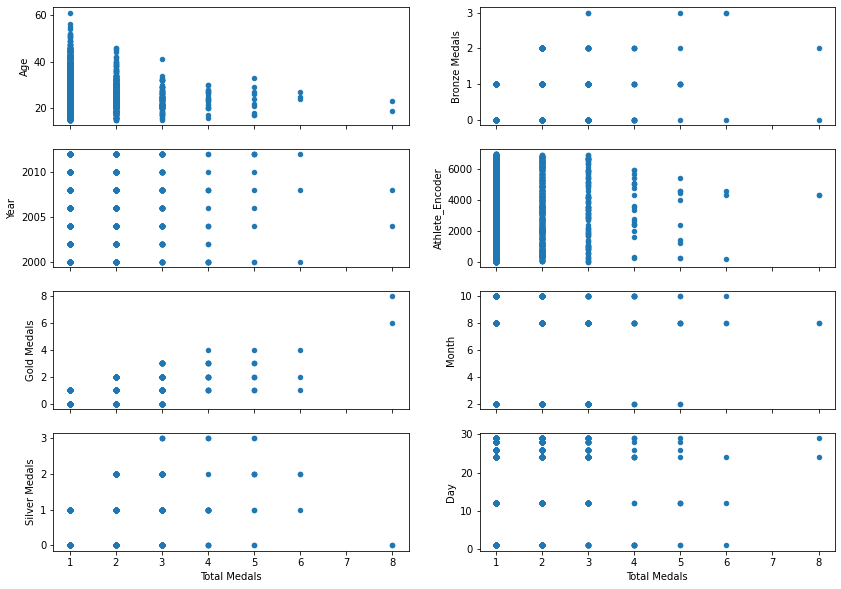

In [501]:
# Total Medals
figure, axs = plt.subplots(4,2,figsize = (14,10), sharey=False, sharex=True)
df2.plot(kind="scatter",x=columnas[5],y=columnas[0],ax=axs[0][0])
df2.plot(kind="scatter",x=columnas[5],y=columnas[1],ax=axs[1][0])
df2.plot(kind="scatter",x=columnas[5],y=columnas[2],ax=axs[2][0])
df2.plot(kind="scatter",x=columnas[5],y=columnas[3],ax=axs[3][0])
df2.plot(kind="scatter",x=columnas[5],y=columnas[4],ax=axs[0][1])
df2.plot(kind="scatter",x=columnas[5],y=columnas[6],ax=axs[1][1])
df2.plot(kind="scatter",x=columnas[5],y=columnas[7],ax=axs[2][1])
df2.plot(kind="scatter",x=columnas[5],y=columnas[8],ax=axs[3][1])

In [479]:
# Athlete_Encoder
print(np.corrcoef(df2[columnas[6]],df2[columnas[0]])[0,1])
print(np.corrcoef(df2[columnas[6]],df2[columnas[1]])[0,1])
print(np.corrcoef(df2[columnas[6]],df2[columnas[2]])[0,1])
print(np.corrcoef(df2[columnas[6]],df2[columnas[3]])[0,1])
print(np.corrcoef(df2[columnas[6]],df2[columnas[4]])[0,1])
print(np.corrcoef(df2[columnas[6]],df2[columnas[5]])[0,1])
print(np.corrcoef(df2[columnas[6]],df2[columnas[7]])[0,1])
print(np.corrcoef(df2[columnas[6]],df2[columnas[8]])[0,1])

-0.017484472904897568
-0.013778698676566455
0.0034251468309624434
-0.002922067106928134
-0.01056290099830229
-0.012130793230428448
0.03476123799705732
-0.009695510308160096


<AxesSubplot:xlabel='Athlete_Encoder', ylabel='Day'>

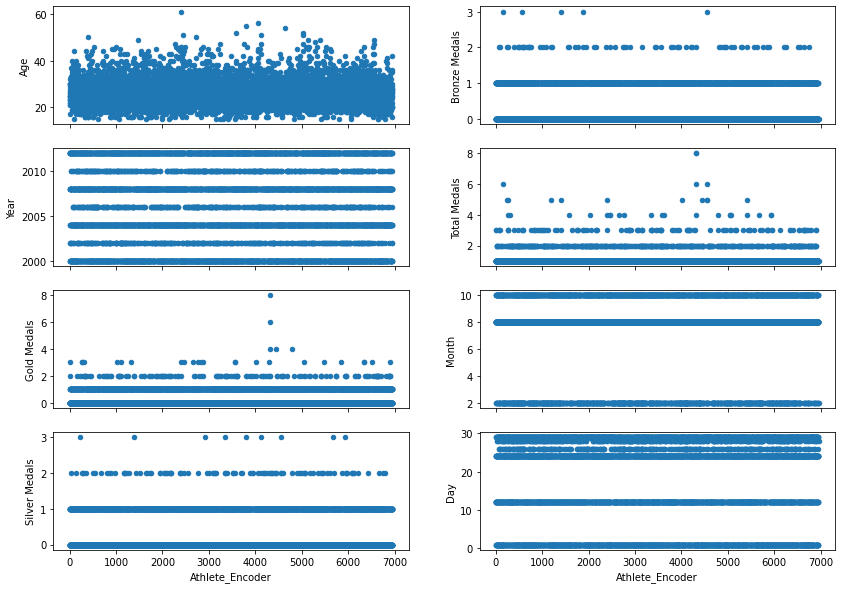

In [502]:
# Athlete_Encoder
figure, axs = plt.subplots(4,2,figsize = (14,10), sharey=False, sharex=True)
df2.plot(kind="scatter",x=columnas[6],y=columnas[0],ax=axs[0][0])
df2.plot(kind="scatter",x=columnas[6],y=columnas[1],ax=axs[1][0])
df2.plot(kind="scatter",x=columnas[6],y=columnas[2],ax=axs[2][0])
df2.plot(kind="scatter",x=columnas[6],y=columnas[3],ax=axs[3][0])
df2.plot(kind="scatter",x=columnas[6],y=columnas[4],ax=axs[0][1])
df2.plot(kind="scatter",x=columnas[6],y=columnas[5],ax=axs[1][1])
df2.plot(kind="scatter",x=columnas[6],y=columnas[7],ax=axs[2][1])
df2.plot(kind="scatter",x=columnas[6],y=columnas[8],ax=axs[3][1])

In [513]:
# Month
print(np.corrcoef(df2[columnas[7]],df2[columnas[0]])[0,1])
print(np.corrcoef(df2[columnas[7]],df2[columnas[1]])[0,1])
print(np.corrcoef(df2[columnas[7]],df2[columnas[2]])[0,1])
print(np.corrcoef(df2[columnas[7]],df2[columnas[3]])[0,1])
print(np.corrcoef(df2[columnas[7]],df2[columnas[4]])[0,1])
print(np.corrcoef(df2[columnas[7]],df2[columnas[5]])[0,1])
print(np.corrcoef(df2[columnas[7]],df2[columnas[6]])[0,1])
print(np.corrcoef(df2[columnas[7]],df2[columnas[8]])[0,1])

print("Valor más cercano a 1 : ",np.corrcoef(df2[columnas[7]],df2[columnas[8]])[0,1])

-0.05792824499131946
-0.25358266837342847
-0.02273976347006791
-0.022585178343374562
-0.01230277883701616
-0.0737644737337412
0.03476123799705731
-0.5561135625315325
Valor más cercano a 1 :  -0.5561135625315325


<AxesSubplot:xlabel='Month', ylabel='Day'>

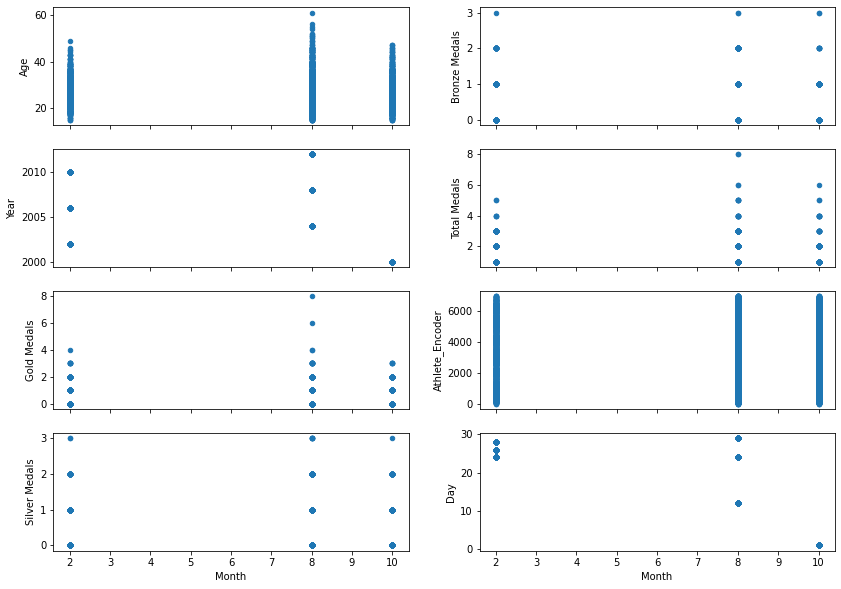

In [504]:
# Month

figure, axs = plt.subplots(4,2,figsize = (14,10), sharey=False, sharex=True)
df2.plot(kind="scatter",x=columnas[7],y=columnas[0],ax=axs[0][0])
df2.plot(kind="scatter",x=columnas[7],y=columnas[1],ax=axs[1][0])
df2.plot(kind="scatter",x=columnas[7],y=columnas[2],ax=axs[2][0])
df2.plot(kind="scatter",x=columnas[7],y=columnas[3],ax=axs[3][0])
df2.plot(kind="scatter",x=columnas[7],y=columnas[4],ax=axs[0][1])
df2.plot(kind="scatter",x=columnas[7],y=columnas[5],ax=axs[1][1])
df2.plot(kind="scatter",x=columnas[7],y=columnas[6],ax=axs[2][1])
df2.plot(kind="scatter",x=columnas[7],y=columnas[8],ax=axs[3][1])

In [515]:
# Day
print(np.corrcoef(df2[columnas[8]],df2[columnas[0]])[0,1])
print(np.corrcoef(df2[columnas[8]],df2[columnas[1]])[0,1])
print(np.corrcoef(df2[columnas[8]],df2[columnas[2]])[0,1])
print(np.corrcoef(df2[columnas[8]],df2[columnas[3]])[0,1])
print(np.corrcoef(df2[columnas[8]],df2[columnas[4]])[0,1])
print(np.corrcoef(df2[columnas[8]],df2[columnas[5]])[0,1])
print(np.corrcoef(df2[columnas[8]],df2[columnas[6]])[0,1])
print(np.corrcoef(df2[columnas[8]],df2[columnas[7]])[0,1])

print("Valor más cercano a 1 :", np.corrcoef(df2[columnas[8]],df2[columnas[7]])[0,1])

0.022992325663340366
0.28994273092554984
0.008331459529052355
0.008069896265713972
0.0032347333301907806
0.025197993783196367
-0.009695510308160096
-0.5561135625315325
Valor más cercano a 1 : -0.5561135625315325


<AxesSubplot:xlabel='Day', ylabel='Month'>

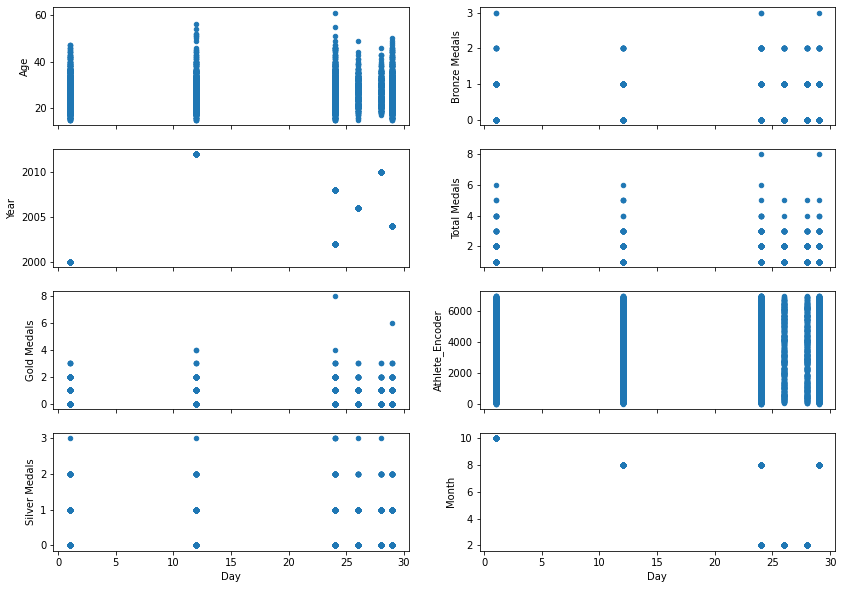

In [516]:
# Day
figure, axs = plt.subplots(4,2,figsize = (14,10), sharey=False, sharex=True)
df2.plot(kind="scatter",x=columnas[8],y=columnas[0],ax=axs[0][0])
df2.plot(kind="scatter",x=columnas[8],y=columnas[1],ax=axs[1][0])
df2.plot(kind="scatter",x=columnas[8],y=columnas[2],ax=axs[2][0])
df2.plot(kind="scatter",x=columnas[8],y=columnas[3],ax=axs[3][0])
df2.plot(kind="scatter",x=columnas[8],y=columnas[4],ax=axs[0][1])
df2.plot(kind="scatter",x=columnas[8],y=columnas[5],ax=axs[1][1])
df2.plot(kind="scatter",x=columnas[8],y=columnas[6],ax=axs[2][1])
df2.plot(kind="scatter",x=columnas[8],y=columnas[7],ax=axs[3][1])

In [519]:
# Varibles 

print("Valor más cercano a 1 :", np.corrcoef(df2[columnas[2]],df2[columnas[4]])[0,1])
print("Valor más cercano a 1 :", np.corrcoef(df2[columnas[4]],df2[columnas[2]])[0,1])

print("Valor más cercano a 1 :",np.corrcoef(df2[columnas[3]],df2[columnas[4]])[0,1])
print("Valor más cercano a 1 :",np.corrcoef(df2[columnas[4]],df2[columnas[3]])[0,1])

print("Valor más cercano a 1 :",np.corrcoef(df2[columnas[5]],df2[columnas[2]])[0,1])
print("Valor más cercano a 1 :",np.corrcoef(df2[columnas[2]],df2[columnas[5]])[0,1])

print("Valor más cercano a 1 : ",np.corrcoef(df2[columnas[7]],df2[columnas[8]])[0,1])
print("Valor más cercano a 1 :", np.corrcoef(df2[columnas[8]],df2[columnas[7]])[0,1])

Valor más cercano a 1 : -0.4032914048970575
Valor más cercano a 1 : -0.4032914048970575
Valor más cercano a 1 : -0.4455619788883029
Valor más cercano a 1 : -0.4455619788883029
Valor más cercano a 1 : 0.39952152953813214
Valor más cercano a 1 : 0.39952152953813214
Valor más cercano a 1 :  -0.5561135625315325
Valor más cercano a 1 : -0.5561135625315325


<AxesSubplot:xlabel='Gold Medals', ylabel='Bronze Medals'>

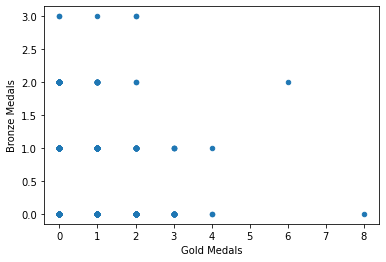

In [520]:
df2.plot(kind="scatter",x=columnas[2],y=columnas[4])

<AxesSubplot:xlabel='Bronze Medals', ylabel='Gold Medals'>

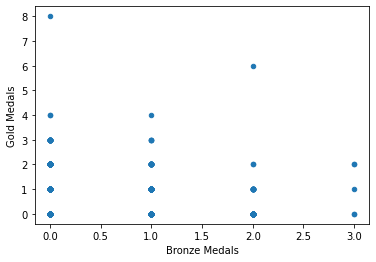

In [521]:
df2.plot(kind="scatter",x=columnas[4],y=columnas[2])

<AxesSubplot:xlabel='Silver Medals', ylabel='Bronze Medals'>

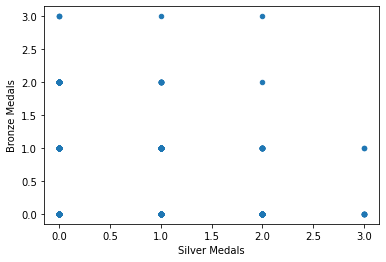

In [522]:
df2.plot(kind="scatter",x=columnas[3],y=columnas[4])

<AxesSubplot:xlabel='Bronze Medals', ylabel='Silver Medals'>

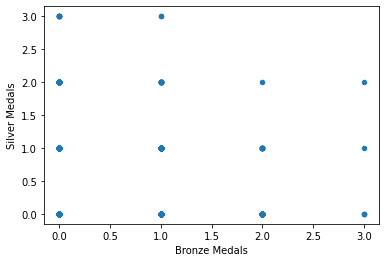

In [523]:
df2.plot(kind="scatter",x=columnas[4],y=columnas[3])

<AxesSubplot:xlabel='Total Medals', ylabel='Gold Medals'>

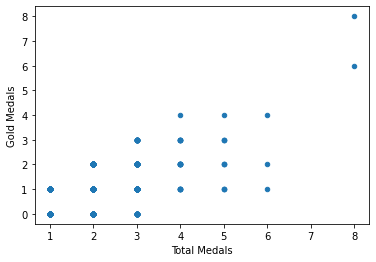

In [524]:
df2.plot(kind="scatter",x=columnas[5],y=columnas[2])

<AxesSubplot:xlabel='Gold Medals', ylabel='Total Medals'>

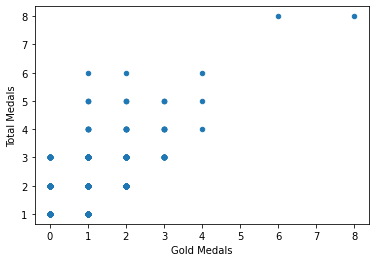

In [525]:
df2.plot(kind="scatter",x=columnas[2],y=columnas[5])

<AxesSubplot:xlabel='Month', ylabel='Day'>

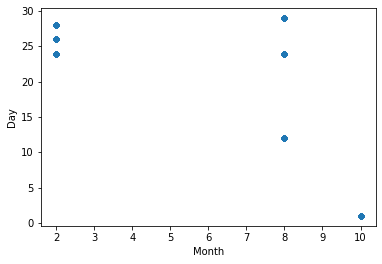

In [526]:
df2.plot(kind="scatter",x=columnas[7],y=columnas[8])

<AxesSubplot:xlabel='Day', ylabel='Month'>

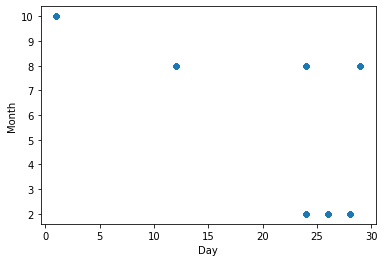

In [527]:
df2.plot(kind="scatter",x=columnas[8],y=columnas[7])

In [528]:
df2[columnas[2]].describe

<bound method NDFrame.describe of Closing Ceremony Date
2008-08-24    8
2004-08-29    6
2012-08-12    4
2008-08-24    1
2000-10-01    2
             ..
2000-10-01    0
2000-10-01    0
2000-10-01    0
2000-10-01    0
2000-10-01    0
Name: Gold Medals, Length: 8613, dtype: int64>

In [529]:
df2[columnas[4]].describe

<bound method NDFrame.describe of Closing Ceremony Date
2008-08-24    0
2004-08-29    2
2012-08-12    0
2008-08-24    3
2000-10-01    3
             ..
2000-10-01    0
2000-10-01    0
2000-10-01    1
2000-10-01    1
2000-10-01    1
Name: Bronze Medals, Length: 8613, dtype: int64>

In [ ]:
# Regresión Lineal
petal_X = df["Petal.Length"]
petal_y = df["Petal.Width"]

petal_X_train = petal_X.iloc[:-20].values
petal_X_test = petal_X.iloc[-20:].values

petal_y_train = petal_y.iloc[:-20].values
petal_y_test = petal_y.iloc[-20:].values